<a href="https://colab.research.google.com/github/huynhtanthanhwqu/CHUNG-CHI/blob/main/MScFE600_GWP1_Code_Group18255.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Downloading IVV Data ---


/tmp/ipykernel_1215/2947213434.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("IVV", start="2021-01-01", end="2025-12-31")
[*********************100%***********************]  1 of 1 completed


Fold 1 Accuracy: 0.5182
Fold 2 Accuracy: 0.4899
Fold 3 Accuracy: 0.5182
Fold 4 Accuracy: 0.4899
Fold 5 Accuracy: 0.4797

--- Model Performance Table ---
   Fold  Accuracy
 Fold 1  0.518219
 Fold 2  0.489879
 Fold 3  0.518219
 Fold 4  0.489879
 Fold 5  0.479675
Average  0.499174


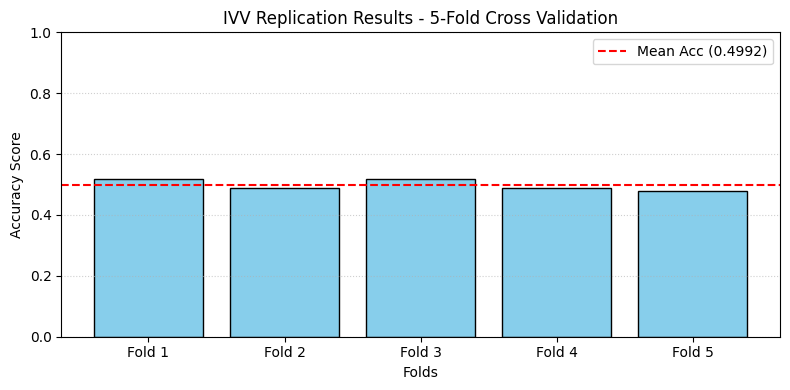

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. Download historical data for IVV ETF from Yahoo Finance
print("--- Downloading IVV Data ---")
df = yf.download("IVV", start="2021-01-01", end="2025-12-31")

# 2. Feature Engineering: Calculate daily returns and rolling standard deviation (dispersion metric)
df['Return'] = df['Close'].pct_change()
df['Volatility_20d'] = df['Return'].rolling(window=20).std()

# Define binary classification target: 1 if next day return is positive, 0 otherwise
df['Target'] = np.where(df['Return'].shift(-1) > 0, 1, 0)

# Drop missing values
df.dropna(inplace=True)

# Define features (X) and target variable (y)
X = df[['Volatility_20d']].values
y = df['Target'].values

# 3. Implement 5-Fold Cross-Validation Framework
kf = KFold(n_splits=5, shuffle=False)
model = RandomForestClassifier(n_estimators=50, random_state=42)

fold_accuracies = []
fold = 1

for train_index, test_index in kf.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Train the classification model
    model.fit(X_train, y_train)

    # Predict and calculate validation accuracy
    predictions = model.predict(X_test)
    acc = accuracy_score(y_test, predictions)
    fold_accuracies.append(acc)

    print(f"Fold {fold} Accuracy: {acc:.4f}")
    fold += 1

# 4. Generate Performance Results Table
result_table = pd.DataFrame({
    'Fold': [f"Fold {i}" for i in range(1, 6)],
    'Accuracy': fold_accuracies
})
result_table.loc[len(result_table)] = ['Average', np.mean(fold_accuracies)]
print("\n--- Model Performance Table ---")
print(result_table.to_string(index=False))

# 5. Plot and Save Replication Graph
plt.figure(figsize=(8, 4))
plt.bar(result_table['Fold'][:-1], fold_accuracies, color='skyblue', edgecolor='black')
plt.axhline(y=np.mean(fold_accuracies), color='red', linestyle='--', label=f"Mean Acc ({np.mean(fold_accuracies):.4f})")
plt.title("IVV Replication Results - 5-Fold Cross Validation")
plt.xlabel("Folds")
plt.ylabel("Accuracy Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig("replication_graph.pdf")
plt.show()

In [2]:
import yfinance as yf
import pandas as pd

# Import alternative financial terminal data safely
print("--- Fetching Alternative Terminal Data ---")
ticker = yf.Ticker("IVV")

# Extract clean historical market depth and volume data to avoid rate limits
historical_data = ticker.history(period="1mo")

# Structure into a clean pandas DataFrame for Exploratory Data Analysis (EDA)
df_terminal = pd.DataFrame(historical_data)

print("\n--- First 5 Rows of Structured Terminal Data ---")
print(df_terminal.head())


--- Fetching Alternative Terminal Data ---

--- First 5 Rows of Structured Terminal Data ---
                                 Open        High         Low       Close  \
Date                                                                        
2026-09-10 00:00:00-04:00  759.415236  761.539103  758.109013  759.335510   
2026-09-11 00:00:00-04:00  766.185750  767.840940  765.108846  765.707092   
2026-09-14 00:00:00-04:00  760.442314  764.939327  759.355428  762.276978   
2026-09-15 00:00:00-04:00  761.580017  761.760010  757.590027  758.880005   
2026-09-16 00:00:00-04:00  760.919983  763.039978  751.020020  755.630005   

                             Volume  Dividends  Stock Splits  Capital Gains  
Date                                                                         
2026-09-10 00:00:00-04:00  17463500      0.000           0.0            0.0  
2026-09-11 00:00:00-04:00   7580100      0.000           0.0            0.0  
2026-09-14 00:00:00-04:00   4580000      0.000         